In [6]:
import matplotlib.pyplot as plt
from pathlib import Path
import sys

import pandas as pd
from sklearn.model_selection import train_test_split

sys.path.append(str(Path("..").resolve()))

from src.data import load_raw_data, split_features_target

DATA_PATH = Path("../data/raw/Telco-Customer-Churn.csv")
RANDOM_STATE = 42

df = load_raw_data(DATA_PATH)
X, y = split_features_target(df)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    stratify=y_train_val,
    random_state=RANDOM_STATE
)

print("Train set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Held-out test set:", X_test.shape)

Train set: (4225, 19)
Validation set: (1409, 19)
Held-out test set: (1409, 19)


In [2]:
import numpy as np

def add_features(data):
    result = data.copy()

    service_columns = [
        "PhoneService",
        "MultipleLines",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]

    result["ServiceCount"] = result[service_columns].eq("Yes").sum(axis=1)

    result["TenureGroup"] = pd.cut(
        result["tenure"],
        bins=[-1, 6, 12, 24, 48, float("inf")],
        labels=["0-6", "7-12", "13-24", "25-48", "49+"]
    )

    result["MonthlyChargesPerTenure"] = np.where(
        result["tenure"] > 0,
        result["MonthlyCharges"] / result["tenure"],
        0
    )

    return result

X_train_features = add_features(X_train)
X_val_features = add_features(X_val)
X_test_features = add_features(X_test)

X_train_features.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,ServiceCount,TenureGroup,MonthlyChargesPerTenure
2312,Male,0,No,No,18,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,One year,No,Mailed check,20.10,401.85,1,13-24,1.116667
5227,Male,0,No,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,No,Electronic check,96.20,639.70,4,7-12,13.742857
6404,Male,0,No,No,52,Yes,Yes,Fiber optic,Yes,No,...,Yes,Yes,Two year,Yes,Electronic check,109.30,5731.40,7,49+,2.101923
88,Female,0,Yes,Yes,46,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Two year,Yes,Mailed check,19.95,927.10,1,25-48,0.433696
6496,Male,1,Yes,No,40,Yes,Yes,Fiber optic,Yes,No,...,Yes,Yes,Month-to-month,No,Electronic check,101.85,4086.30,5,25-48,2.546250


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train_features.select_dtypes(include="number").columns.tolist()
categorical_features = X_train_features.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train_features, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['gender','SeniorCitizen','Partner',...,'ServiceCount','TenureGroup', 'MonthlyChargesPerTenure']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [9]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score

comparison_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
            ]),
            categorical_features
        )
    ]
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=15,
        weights="distance"
    ),
    "Linear SVM": SVC(
        kernel="linear",
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ),
    "Kernel SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=15,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for model_name, classifier in models.items():
    model = Pipeline([
        ("preprocessor", clone(comparison_preprocessor)),
        ("classifier", classifier)
    ])

    model.fit(X_train_features, y_train)

    probabilities = model.predict_proba(X_val_features)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "model": model_name,
        "recall": recall_score(y_val, predictions, zero_division=0),
        "precision": precision_score(y_val, predictions, zero_division=0),
        "f1": f1_score(y_val, predictions, zero_division=0),
        "pr_auc": average_precision_score(y_val, probabilities)
    })

    trained_models[model_name] = model

model_comparison = (
    pd.DataFrame(results)
    .sort_values("pr_auc", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

model_comparison

c:\Users\alexk\OneDrive\Desktop\customer-churn-predictor\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\alexk\OneDrive\Desktop\customer-churn-predictor\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,model,recall,precision,f1,pr_auc
0,Logistic Regression,0.7781,0.5196,0.6231,0.6543
1,Linear SVM,0.0000,0.0000,0.0000,0.6515
2,Random Forest,0.7059,0.5511,0.6190,0.6323
3,Gaussian Naive Bayes,0.8128,0.4743,0.5990,0.6259
4,Kernel SVM,0.6123,0.6139,0.6131,0.5797
5,Decision Tree,0.7487,0.4912,0.5932,0.5700
6,K-Nearest Neighbors,0.4786,0.5737,0.5219,0.5659


In [10]:
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

best_model = trained_models["Logistic Regression"]
probabilities = best_model.predict_proba(X_val_features)[:, 1]

threshold_results = []

for threshold in thresholds:
    predictions = (probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "recall": recall_score(y_val, predictions, zero_division=0),
        "precision": precision_score(y_val, predictions, zero_division=0),
        "f1": f1_score(y_val, predictions, zero_division=0)
    })

threshold_comparison = (
    pd.DataFrame(threshold_results)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

threshold_comparison

,threshold,recall,precision,f1
0,0.60,0.7086,0.5786,0.6370
1,0.55,0.7326,0.5437,0.6241
2,0.50,0.7781,0.5196,0.6231
3,0.45,0.8235,0.5000,0.6222
4,0.40,0.8449,0.4627,0.5979
5,0.35,0.8850,0.4419,0.5895
6,0.30,0.9064,0.4216,0.5756


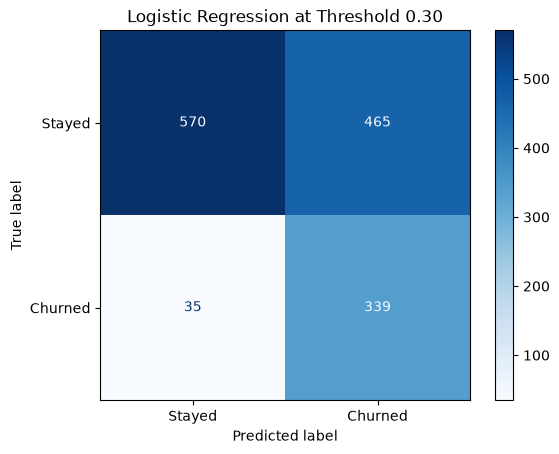

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

chosen_threshold = 0.30
chosen_model = trained_models["Logistic Regression"]

probabilities = chosen_model.predict_proba(X_val_features)[:, 1]
predictions = (probabilities >= chosen_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title("Logistic Regression at Threshold 0.30")
plt.show()

### Model selection

Logistic Regression achieved the highest PR-AUC (0.6543) among the tested models. A threshold of 0.30 was selected because it identifies 90.64% of customers who churned on the validation set. This threshold is appropriate when the business prioritizes proactive retention over minimizing false-positive outreach.

,model,threshold,recall,precision,f1,pr_auc
0,Logistic Regression,0.3,0.9305,0.4345,0.5923,0.6666


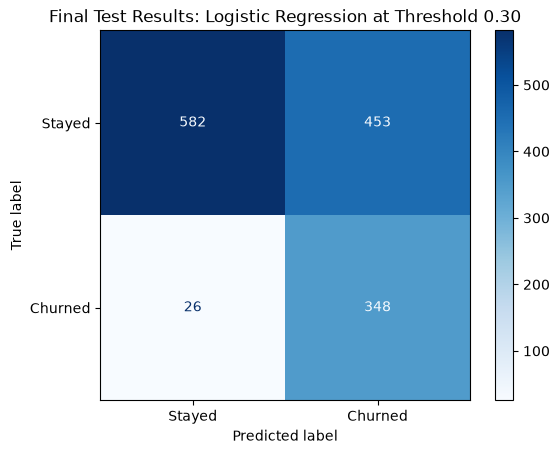

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

chosen_threshold = 0.30

X_train_final = pd.concat([X_train_features, X_val_features])
y_train_final = pd.concat([y_train, y_val])

final_model = trained_models["Logistic Regression"]
final_model.fit(X_train_final, y_train_final)

test_probabilities = final_model.predict_proba(X_test_features)[:, 1]
test_predictions = (test_probabilities >= chosen_threshold).astype(int)

final_test_metrics = pd.DataFrame([{
    "model": "Logistic Regression",
    "threshold": chosen_threshold,
    "recall": recall_score(y_test, test_predictions, zero_division=0),
    "precision": precision_score(y_test, test_predictions, zero_division=0),
    "f1": f1_score(y_test, test_predictions, zero_division=0),
    "pr_auc": average_precision_score(y_test, test_probabilities)
}]).round(4)

display(final_test_metrics)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title("Final Test Results: Logistic Regression at Threshold 0.30")
plt.show()

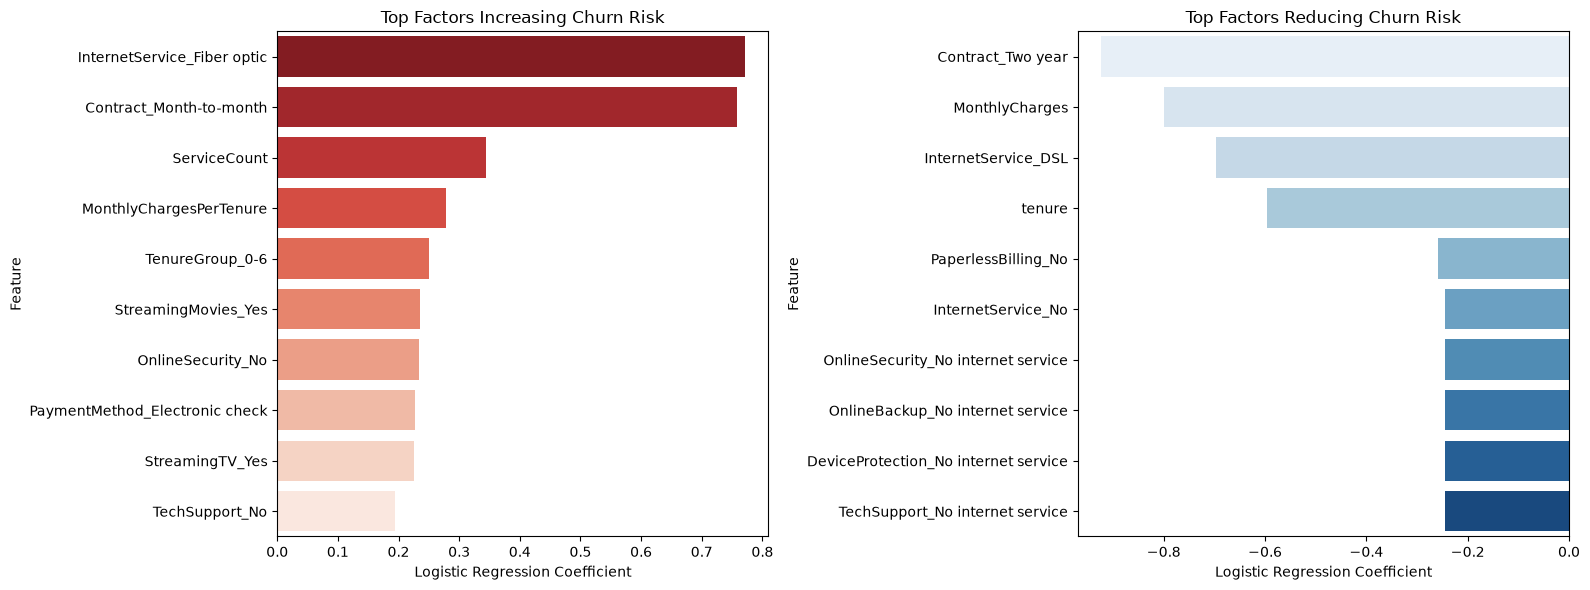

In [13]:
import seaborn as sns

feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = final_model.named_steps["classifier"].coef_[0]

feature_effects = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

feature_effects["feature"] = feature_effects["feature"].str.replace(
    r"^(numeric|categorical)__",
    "",
    regex=True
)

top_risk_factors = feature_effects.nlargest(10, "coefficient")
top_retention_factors = feature_effects.nsmallest(10, "coefficient")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=top_risk_factors,
    x="coefficient",
    y="feature",
    hue="feature",
    palette="Reds_r",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Top Factors Increasing Churn Risk")
axes[0].set_xlabel("Logistic Regression Coefficient")
axes[0].set_ylabel("Feature")

sns.barplot(
    data=top_retention_factors,
    x="coefficient",
    y="feature",
    hue="feature",
    palette="Blues",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Top Factors Reducing Churn Risk")
axes[1].set_xlabel("Logistic Regression Coefficient")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()

### Key business insights

The highest churn-risk segments are customers with fiber optic internet, month-to-month contracts, and short tenure. Customers without Online Security or Tech Support also show higher churn risk.

Two-year contracts and longer customer tenure are strongly associated with lower churn risk. Retention efforts should prioritize early-life customers on month-to-month fiber optic plans and consider offers that encourage longer contracts or provide support-related services.

Model coefficients show associations rather than causal effects.

In [14]:
from pathlib import Path
import joblib

model_directory = Path("../models")
model_directory.mkdir(exist_ok=True)

model_artifact = {
    "model": final_model,
    "threshold": chosen_threshold,
    "model_name": "Logistic Regression",
    "test_metrics": final_test_metrics.to_dict(orient="records")[0]
}

model_path = model_directory / "churn_model.joblib"

joblib.dump(model_artifact, model_path)

print(f"Model saved to: {model_path.resolve()}")
print(model_artifact["test_metrics"])

Model saved to: C:\Users\alexk\OneDrive\Desktop\customer-churn-predictor\models\churn_model.joblib
{'model': 'Logistic Regression', 'threshold': 0.3, 'recall': 0.9305, 'precision': 0.4345, 'f1': 0.5923, 'pr_auc': 0.6666}
